# Remaining marine radar encoders: ResNet-18, ConvNeXt-Tiny, Swin-Tiny

Run every cell in order in a GPU Colab runtime. All definitions are included. This notebook restores your saved paired manifest and four-class mask mapping, trains only the three new encoders, and produces a six-model comparison using existing baseline checkpoints. It keeps ALL branches pooled and uses the existing train/val/test splits.

The completed log reports baseline **validation** Dice: custom U-Net 0.887929, ResNet-34 0.919662, EfficientNet-B0 0.925186. These are not test results. Test evaluation is a separate final cell.

Your custom baseline has a smaller decoder than SMP U-Net. The five pretrained models use the same SMP U-Net decoder settings, although the hierarchical backbones expose different skip features. Thus this is an architecture benchmark rather than a strictly isolated encoder ablation.


In [1]:
!pip -q install segmentation-models-pytorch==0.5.0 timm==1.0.20


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.7/61.7 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 41.4 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')
from pathlib import Path
import os, re, json, random, time, csv, shutil
from collections import Counter, defaultdict
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
import segmentation_models_pytorch as smp
from tqdm.auto import tqdm

ROOT = Path('/content/drive/MyDrive/Radar Dataset')
OUT = Path('/content/drive/MyDrive/radar_unet_results')
OUT.mkdir(parents=True, exist_ok=True)
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device:', DEVICE, 'dataset exists:', ROOT.is_dir())
assert ROOT.is_dir(), 'Change ROOT to the actual Google Drive dataset location.'
assert DEVICE=='cuda', 'Select Runtime > Change runtime type > GPU, then run setup again.'
print('GPU:',torch.cuda.get_device_name(0))


Mounted at /content/drive
device: cuda dataset exists: True
GPU: Tesla T4


## 1. Restore the saved paired manifest

This reads `paired_manifest.csv`, not every image pixel. Image and mask files retain their original Drive paths. It confirms the 2,520/420/420 counts and preserves the original split. A missing manifest stops with a clear instruction instead of repeating the expensive audit.


In [7]:
manifest_path=OUT/'paired_manifest.csv'
if not manifest_path.is_file():
    raise FileNotFoundError(f'{manifest_path} is missing. Run only the original notebook cell that discovers branches and pairs filenames to recreate it. The color/dimension scans are unnecessary.')
with open(manifest_path,newline='') as f: rows=list(csv.DictReader(f))
SPLITS=('train','val','test')
required={'branch','split','rep','key','image','mask'}
assert rows and required.issubset(rows[0]), 'Invalid manifest columns.'
counts=Counter(r['split'] for r in rows)
print('Split counts:',dict(counts))
assert dict(counts)=={'train':2520,'val':420,'test':420}, 'Inventory changed: inspect before comparing models.'


Split counts: {'train': 2520, 'val': 420, 'test': 420}


## 2. Restore the four audited mask classes

Black=0, green=1, blue=2, red=3. The 13 rare neutral-gray shades from the previous full audit are provisionally mapped to background. The original class meanings must be checked against the dataset label guide. Unexpected colors cause an error; masks are never resized with bilinear interpolation.


In [8]:
def pack(rgb):
    a=rgb.astype(np.uint32)
    return (a[...,0]<<16)|(a[...,1]<<8)|a[...,2]
def unpack(k):return [int((k>>16)&255),int((k>>8)&255),int(k&255)]
PALETTE=[0x000000,0x00ff00,0x0000ff,0xff0000]
NUM_CLASSES=4
NEUTRAL_ARTIFACTS={(v<<16)|(v<<8)|v for v in [34,51,68,85,102,119,136,153,170,187,204,221,238]}
def mask_to_ids(rgb):
    packed=pack(rgb);ids=np.full(packed.shape,255,np.uint8)
    for i,color in enumerate(PALETTE):ids[packed==color]=i
    for color in NEUTRAL_ARTIFACTS:ids[packed==color]=0
    if np.any(ids==255):
        raise ValueError('Unexpected mask colors: '+str([unpack(int(k)) for k in np.unique(packed[ids==255])[:10]]))
    return ids
print('Classes:',{i:unpack(k) for i,k in enumerate(PALETTE)})


Classes: {0: [0, 0, 0], 1: [0, 255, 0], 2: [0, 0, 255], 3: [255, 0, 0]}


## 3. Dataset and models

Resolution is restored from your saved ResNet-34 checkpoint. Batch size is 8, maximum epochs 20, patience 5, and learning rate 0.0002, matching the supplied run. If a new model exceeds GPU memory, lower BATCH_SIZE before training and record that change in your experiment report. Reducing image resolution would change the comparison.

Swin receives the configured image size explicitly. SMP's universal timm encoder converts its channel-last features to the format used by U-Net. ConvNeXt uses the same universal interface.


In [9]:
from torchvision.transforms import functional as TF
# Restore the actual baseline resolution instead of guessing from notebook defaults.
reference=OUT/'ALL_resnet34'/'best.pt'
assert reference.is_file(), 'ResNet-34 baseline checkpoint is missing from OUT.'
reference_ck=torch.load(reference,map_location='cpu',weights_only=False)
assert reference_ck['palette']==PALETTE and reference_ck['num_classes']==NUM_CLASSES
IMAGE_SIZE=tuple(reference_ck['image_size'])
del reference_ck
assert all(s%32==0 for s in IMAGE_SIZE), 'Use dimensions divisible by 32.'
BATCH_SIZE=8
NUM_WORKERS=2
EPOCHS=20
PATIENCE=5
LR=2e-4
USE_IMAGENET=True
# Change to None to use all discovered representation branches in each pooled model.
# 'CARTESIAN' and 'POLAR' run separate representation experiments.
REPRESENTATION_RUNS=['ALL']

class RadarDataset(Dataset):
    def __init__(self, items, train=False): self.items=items; self.train=train
    def __len__(self): return len(self.items)
    def __getitem__(self,i):
        r=self.items[i]
        with Image.open(r['image']) as im:
            x=im.convert('RGB').resize(IMAGE_SIZE[::-1],Image.Resampling.BILINEAR)
            x=np.array(x,copy=True)
        with Image.open(r['mask']) as im:
            y=im.convert('RGB').resize(IMAGE_SIZE[::-1],Image.Resampling.NEAREST)
            y=mask_to_ids(np.asarray(y))
        x=torch.from_numpy(np.ascontiguousarray(x)).permute(2,0,1).float()/255.
        y=torch.from_numpy(np.ascontiguousarray(y)).long()
        if self.train:
            # Apply spatial changes jointly. No random flips, rotations or range shifts by default.
            if random.random()<0.5:
                x=(x*random.uniform(.85,1.15)).clamp(0,1)
        x=TF.normalize(x,mean=[.485,.456,.406],std=[.229,.224,.225]) if USE_IMAGENET else x
        return x,y

def subset(rep,split):
    return [r for r in rows if r['split']==split and (rep=='ALL' or r['rep']==rep)]
def loaders(rep):
    return {s:DataLoader(RadarDataset(subset(rep,s),train=(s=='train')),
            batch_size=BATCH_SIZE,shuffle=(s=='train'),num_workers=NUM_WORKERS,
            pin_memory=(DEVICE=='cuda'),persistent_workers=(NUM_WORKERS>0)) for s in SPLITS}

class BasicUNet(torch.nn.Module):
    def __init__(self,k):
        super().__init__()
        def block(a,b): return torch.nn.Sequential(torch.nn.Conv2d(a,b,3,padding=1),torch.nn.BatchNorm2d(b),torch.nn.ReLU(inplace=True),torch.nn.Conv2d(b,b,3,padding=1),torch.nn.BatchNorm2d(b),torch.nn.ReLU(inplace=True))
        self.e1=block(3,32);self.e2=block(32,64);self.e3=block(64,128);self.mid=block(128,256)
        self.d3=block(256+128,128);self.d2=block(128+64,64);self.d1=block(64+32,32)
        self.head=torch.nn.Conv2d(32,k,1)
    def forward(self,x):
        a=self.e1(x);b=self.e2(F.max_pool2d(a,2));c=self.e3(F.max_pool2d(b,2));z=self.mid(F.max_pool2d(c,2))
        z=self.d3(torch.cat([F.interpolate(z,size=c.shape[-2:],mode='bilinear',align_corners=False),c],1))
        z=self.d2(torch.cat([F.interpolate(z,size=b.shape[-2:],mode='bilinear',align_corners=False),b],1))
        z=self.d1(torch.cat([F.interpolate(z,size=a.shape[-2:],mode='bilinear',align_corners=False),a],1))
        return self.head(z)

NEW_MODELS=['resnet18','tu-convnext_tiny','tu-swin_tiny_patch4_window7_224']
ALL_MODELS=['custom_unet','resnet34','efficientnet-b0']+NEW_MODELS
REPRESENTATION_RUNS=['ALL']
USE_IMAGENET=True

def make_model(name,pretrained=True):
    if name=='custom_unet':return BasicUNet(NUM_CLASSES)
    kwargs={'img_size':IMAGE_SIZE} if name.startswith('tu-swin_') else {}
    return smp.Unet(encoder_name=name,encoder_weights='imagenet' if pretrained else None,
                    encoder_depth=5,decoder_channels=(256,128,64,32,16),
                    decoder_use_norm='batchnorm',in_channels=3,classes=NUM_CLASSES,**kwargs)
print('Image size:',IMAGE_SIZE,'batch:',BATCH_SIZE,'epochs:',EPOCHS,'new encoders:',NEW_MODELS)


Image size: (512, 512) batch: 8 epochs: 20 new encoders: ['resnet18', 'tu-convnext_tiny', 'tu-swin_tiny_patch4_window7_224']


## 4. Loss and validation

Cross-entropy plus foreground soft Dice; validation checkpoint selection uses foreground macro Dice. Class 0 is excluded from the macro averages. Full-set confusion matrices aggregate pixels before metrics are calculated. An absent true class is excluded from the macro average; per-class support is retained.

The speed column below measures model forward calls after one warm-up batch, excluding disk reads, host-to-device transfer and loss computation. This differs from the earlier notebook's timer, so all six models are measured again under the same definition.


In [3]:
def seg_loss(logits,y):
    ce=F.cross_entropy(logits,y)
    probs=logits.softmax(1)
    target=F.one_hot(y,NUM_CLASSES).permute(0,3,1,2).float()
    axes=(0,2,3)
    dice=(2*(probs*target).sum(axes)+1)/((probs+target).sum(axes)+1)
    return ce + (1-dice[1:].mean())

def empty_cm(): return torch.zeros((NUM_CLASSES,NUM_CLASSES),dtype=torch.int64)
def add_cm(cm,pred,target):
    flat=(target.flatten()*NUM_CLASSES+pred.flatten()).to(torch.int64)
    cm+=torch.bincount(flat,minlength=NUM_CLASSES**2).reshape(NUM_CLASSES,NUM_CLASSES).cpu()

def metrics(cm):
    tp=cm.diag().double();support=cm.sum(1).double();predicted=cm.sum(0).double()
    dice=(2*tp/(support+predicted).clamp(min=1)).tolist()
    iou=(tp/(support+predicted-tp).clamp(min=1)).tolist()
    prec=(tp/predicted.clamp(min=1)).tolist();rec=(tp/support.clamp(min=1)).tolist()
    active=[j for j in range(1,NUM_CLASSES) if support[j]>0]
    return dict(dice=float(np.mean([dice[j] for j in active])) if active else 0.,
                iou=float(np.mean([iou[j] for j in active])) if active else 0.,
                precision=float(np.mean([prec[j] for j in active])) if active else 0.,
                recall=float(np.mean([rec[j] for j in active])) if active else 0.,
                per_class={str(j):dict(dice=dice[j],iou=iou[j],precision=prec[j],recall=rec[j],pixels=int(support[j])) for j in range(NUM_CLASSES)})


def evaluate(model,loader):
    model.eval();cm=empty_cm();loss_sum=0.;n=0;seconds=0.;timed_n=0
    with torch.inference_mode():
        for batch_id,(x,y) in enumerate(tqdm(loader,desc='Evaluation',leave=False)):
            x=x.to(DEVICE,non_blocking=True);y=y.to(DEVICE,non_blocking=True)
            if batch_id==0:
                with torch.autocast(device_type=DEVICE,enabled=DEVICE=='cuda'):model(x)
            if DEVICE=='cuda':torch.cuda.synchronize()
            t=time.perf_counter()
            with torch.autocast(device_type=DEVICE,enabled=DEVICE=='cuda'):logits=model(x)
            if DEVICE=='cuda':torch.cuda.synchronize()
            seconds+=time.perf_counter()-t;timed_n+=len(x)
            # Calculate reductions in float32 to avoid half-precision sum overflow.
            loss=seg_loss(logits.float(),y)
            add_cm(cm,logits.argmax(1),y);loss_sum+=loss.item()*len(x);n+=len(x)
    assert n>0
    return dict(loss=loss_sum/n,**metrics(cm),ms_per_image=1000*seconds/timed_n),cm


## 5. Preflight: one forward pass per new encoder

This catches model names, channel layouts, and input-size problems before a long training run. It is not an evaluation and uses one training image only.


In [16]:
import csv
from pathlib import Path
from collections import Counter

OUT = Path("/content/drive/MyDrive/radar_unet_results")
manifest_path = OUT / "paired_manifest.csv"

if not manifest_path.is_file():
    raise FileNotFoundError(
        f"Missing: {manifest_path}\n"
        "Run the original notebook's filename-pairing cell to recreate it."
    )

with open(manifest_path, newline="") as f:
    rows = list(csv.DictReader(f))

assert rows, "The saved manifest is empty."

required = {"image", "mask", "split", "rep", "branch"}
assert required.issubset(rows[0]), "The manifest has missing columns."

print("Loaded image–mask pairs:", len(rows))
print("Split counts:", dict(Counter(r["split"] for r in rows)))


Loaded image–mask pairs: 3360
Split counts: {'train': 2520, 'val': 420, 'test': 420}


In [14]:
import gc
FORCE_RETRAIN=False

def train_one(model_name,rep='ALL'):
    run=OUT/f'{rep}_{model_name}';run.mkdir(exist_ok=True)
    best_path=run/'best.pt';last_path=run/'last.pt';done_path=run/'training_complete.json'
    def result():
        ck=torch.load(best_path,map_location='cpu',weights_only=False)
        return dict(rep=rep,model=model_name,best_val_dice=ck['val']['dice'],checkpoint=str(best_path))
    if done_path.is_file() and best_path.is_file() and not FORCE_RETRAIN:
        print('Already finished, loading:',model_name);return result()
    random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED);torch.cuda.manual_seed_all(SEED)
    ls=loaders(rep)
    resuming=last_path.is_file() and not FORCE_RETRAIN
    model=make_model(model_name,pretrained=not resuming).to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=1e-4)
    scaler=torch.amp.GradScaler('cuda',enabled=DEVICE=='cuda')
    best=-1.;wait=0;history=[];start=1
    if resuming:
        ck=torch.load(last_path,map_location='cpu',weights_only=False)
        assert ck['image_size']==IMAGE_SIZE and ck['palette']==PALETTE
        assert ck['config']==dict(batch_size=BATCH_SIZE,lr=LR,epochs=EPOCHS,patience=PATIENCE), 'Resume settings changed.'
        model.load_state_dict(ck['state']);optimizer.load_state_dict(ck['optimizer']);scaler.load_state_dict(ck['scaler'])
        best=ck['best'];wait=ck['wait'];history=ck['history'];start=ck['epoch']+1
        random.setstate(ck['python_rng']);np.random.set_state(ck['numpy_rng']);torch.set_rng_state(ck['torch_rng'])
        torch.cuda.set_rng_state_all(ck['cuda_rng'])
        print('Resuming',model_name,'at epoch',start)
        del ck
    # Worker augmentation RNG is not restored exactly; resumed trajectories may differ slightly.
    for epoch in range(start,EPOCHS+1):
        if wait>=PATIENCE:break
        model.train();total=0.;count=0
        for x,y in tqdm(ls['train'],desc=f'{rep} {model_name} {epoch}/{EPOCHS}',leave=False):
            x=x.to(DEVICE,non_blocking=True);y=y.to(DEVICE,non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE,enabled=DEVICE=='cuda'):logits=model(x)
            loss=seg_loss(logits.float(),y)
            if not torch.isfinite(loss):raise RuntimeError('Nonfinite loss; inspect batch and labels.')
            scaler.scale(loss).backward();scaler.step(optimizer);scaler.update()
            total+=loss.item()*len(x);count+=len(x)
        val,_=evaluate(model,ls['val'])
        record=dict(epoch=epoch,train_loss=total/count,**{('val_'+k):v for k,v in val.items() if k!='per_class'})
        history.append(record);print(model_name,record)
        meta=dict(model_name=model_name,rep=rep,num_classes=NUM_CLASSES,palette=PALETTE,image_size=IMAGE_SIZE,epoch=epoch,val=val)
        if val['dice']>best+1e-5:
            best=val['dice'];wait=0;torch.save(dict(state=model.state_dict(),**meta),best_path)
        else:wait+=1
        torch.save(dict(state=model.state_dict(),optimizer=optimizer.state_dict(),scaler=scaler.state_dict(),
                        best=best,wait=wait,history=history,python_rng=random.getstate(),numpy_rng=np.random.get_state(),
                        torch_rng=torch.get_rng_state(),cuda_rng=torch.cuda.get_rng_state_all(),
                        config=dict(batch_size=BATCH_SIZE,lr=LR,epochs=EPOCHS,patience=PATIENCE),**meta),last_path)
        with open(run/'history.json','w') as f:json.dump(history,f,indent=2)
        if wait>=PATIENCE:print('Early stopping');break
    with open(done_path,'w') as f:json.dump(dict(best_val_dice=best,epochs_completed=len(history)),f,indent=2)
    del model,optimizer,scaler,ls;gc.collect();torch.cuda.empty_cache()
    return result()


## 6. Train only the remaining three encoders

Each epoch saves a best checkpoint and a resume checkpoint. Rerunning this cell loads completed runs and resumes interrupted new runs. The baseline checkpoints are untouched. `last.pt` files include optimizer state and use more Drive space than `best.pt`.


In [17]:
SPLITS = ("train", "val", "test")

required = [
    "rows", "subset", "NEW_MODELS", "train_one",
    "RadarDataset", "loaders", "make_model",
    "mask_to_ids", "NUM_CLASSES", "IMAGE_SIZE",
    "BATCH_SIZE", "NUM_WORKERS", "EPOCHS",
    "PATIENCE", "LR", "DEVICE", "OUT", "SEED",
    "seg_loss", "evaluate", "FORCE_RETRAIN",
]
missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        f"Missing definitions: {missing}. "
        "Run the earlier setup and function-definition cells first."
    )

completed_new = []
print(
    "Pooled training/validation/test:",
    *[len(subset("ALL", s)) for s in SPLITS]
)

for name in NEW_MODELS:
    completed_new.append(train_one(name, "ALL"))

print("Completed new experiments:", completed_new)


Pooled training/validation/test: 2520 420 420
Already finished, loading: resnet18
Already finished, loading: tu-convnext_tiny
Already finished, loading: tu-swin_tiny_patch4_window7_224
Completed new experiments: [{'rep': 'ALL', 'model': 'resnet18', 'best_val_dice': 0.9219061391645238, 'checkpoint': '/content/drive/MyDrive/radar_unet_results/ALL_resnet18/best.pt'}, {'rep': 'ALL', 'model': 'tu-convnext_tiny', 'best_val_dice': 0.9231260472870914, 'checkpoint': '/content/drive/MyDrive/radar_unet_results/ALL_tu-convnext_tiny/best.pt'}, {'rep': 'ALL', 'model': 'tu-swin_tiny_patch4_window7_224', 'best_val_dice': 0.919789508175512, 'checkpoint': '/content/drive/MyDrive/radar_unet_results/ALL_tu-swin_tiny_patch4_window7_224/best.pt'}]


## 7. Final six-model test comparison

Run after all new runs are completed and all validation choices are fixed. This loads the best validation checkpoint for each model. It saves `comparison_all6.csv` (new name, preserving the earlier CSV), per-class test metrics and per-branch metrics. Do not use these results to tune hyperparameters.


In [13]:
completed=[]
for name in ALL_MODELS:
    path=OUT/f'ALL_{name}'/'best.pt'
    if not path.is_file():raise FileNotFoundError(f'Missing checkpoint: {path}')
    ck=torch.load(path,map_location='cpu',weights_only=False)
    assert ck['palette']==PALETTE and ck['num_classes']==NUM_CLASSES
    assert tuple(ck['image_size'])==IMAGE_SIZE, 'Checkpoint resolutions differ; do not silently compare at a new resolution.'
    completed.append(dict(rep='ALL',model=name,best_val_dice=ck['val']['dice'],checkpoint=str(path)))
    del ck

scores=[]
for item in completed:
    name=item['model'];model=make_model(name,pretrained=False).to(DEVICE)
    ck=torch.load(item['checkpoint'],map_location='cpu',weights_only=False)
    model.load_state_dict(ck['state']);del ck
    ls=loaders('ALL');score,cm=evaluate(model,ls['test'])
    scores.append(dict(model=name,val_dice=item['best_val_dice'],**{k:v for k,v in score.items() if k!='per_class'}))
    branch_reports={}
    for branch in sorted(set(r['branch'] for r in subset('ALL','test'))):
        items=[r for r in subset('ALL','test') if r['branch']==branch]
        loader=DataLoader(RadarDataset(items),batch_size=BATCH_SIZE,num_workers=NUM_WORKERS,pin_memory=True)
        branch_reports[branch],_=evaluate(model,loader)
    with open(OUT/f'ALL_{name}'/'test_metrics_all6.json','w') as f:
        json.dump(dict(score=score,confusion_matrix=cm.tolist(),branches=branch_reports),f,indent=2)
    print(name,{k:v for k,v in score.items() if k!='per_class'})
    del model,ls,loader;gc.collect();torch.cuda.empty_cache()
with open(OUT/'comparison_all6.csv','w',newline='') as f:
    writer=csv.DictWriter(f,fieldnames=list(scores[0]));writer.writeheader();writer.writerows(scores)
import pandas as pd
display(pd.DataFrame(scores).round(4))
print('Saved:',OUT/'comparison_all6.csv')


Evaluation:   0%|          | 0/53 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/38 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/4 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x798ceb310f40>Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x798ceb310f40>Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
        self._shutdown_workers()self._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
        if w.is_alive():if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        assert self._parent_pid == os.getpid(), 'can only te

Evaluation:   0%|          | 0/4 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/4 [00:00<?, ?it/s]

... (47 outputs left out)

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x798ceb310f40>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x798ceb310f40>  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    
if w.is_alive():Traceback (most recent call last):

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
        self._shutdown_workers()
assert self._parent_pid == os.getpid(), 'can only test a child process'  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

    AssertionError: if w.is_alive():can only test a child process

  File "/usr/lib/

tu-swin_tiny_patch4_window7_224 {'loss': 0.1495364995229812, 'dice': 0.9164917102993453, 'iou': 0.8500785512668524, 'precision': 0.9222152820266709, 'recall': 0.9109340504764006, 'ms_per_image': 17.66491609523709}


,model,val_dice,loss,dice,iou,precision,recall,ms_per_image
0,custom_unet,0.8879,0.7288,0.8830,0.7967,0.8667,0.9003,19.2368
1,resnet34,0.9197,0.1572,0.9091,0.8372,0.9202,0.8990,9.7283
2,efficientnet-b0,0.9252,0.1358,0.9234,0.8612,0.9200,0.9270,10.5366
3,resnet18,0.9219,0.1496,0.9142,0.8457,0.9211,0.9075,7.2433
4,tu-convnext_tiny,0.9231,0.1403,0.9224,0.8598,0.9200,0.9254,17.3455
5,tu-swin_tiny_patch4_window7_224,0.9198,0.1495,0.9165,0.8501,0.9222,0.9109,17.6649


Saved: /content/drive/MyDrive/radar_unet_results/comparison_all6.csv


## 8. Prediction panel for the model chosen by validation Dice

Selection uses validation Dice alone. Ground truth and predictions use the original label RGB colors at the same displayed resolution.


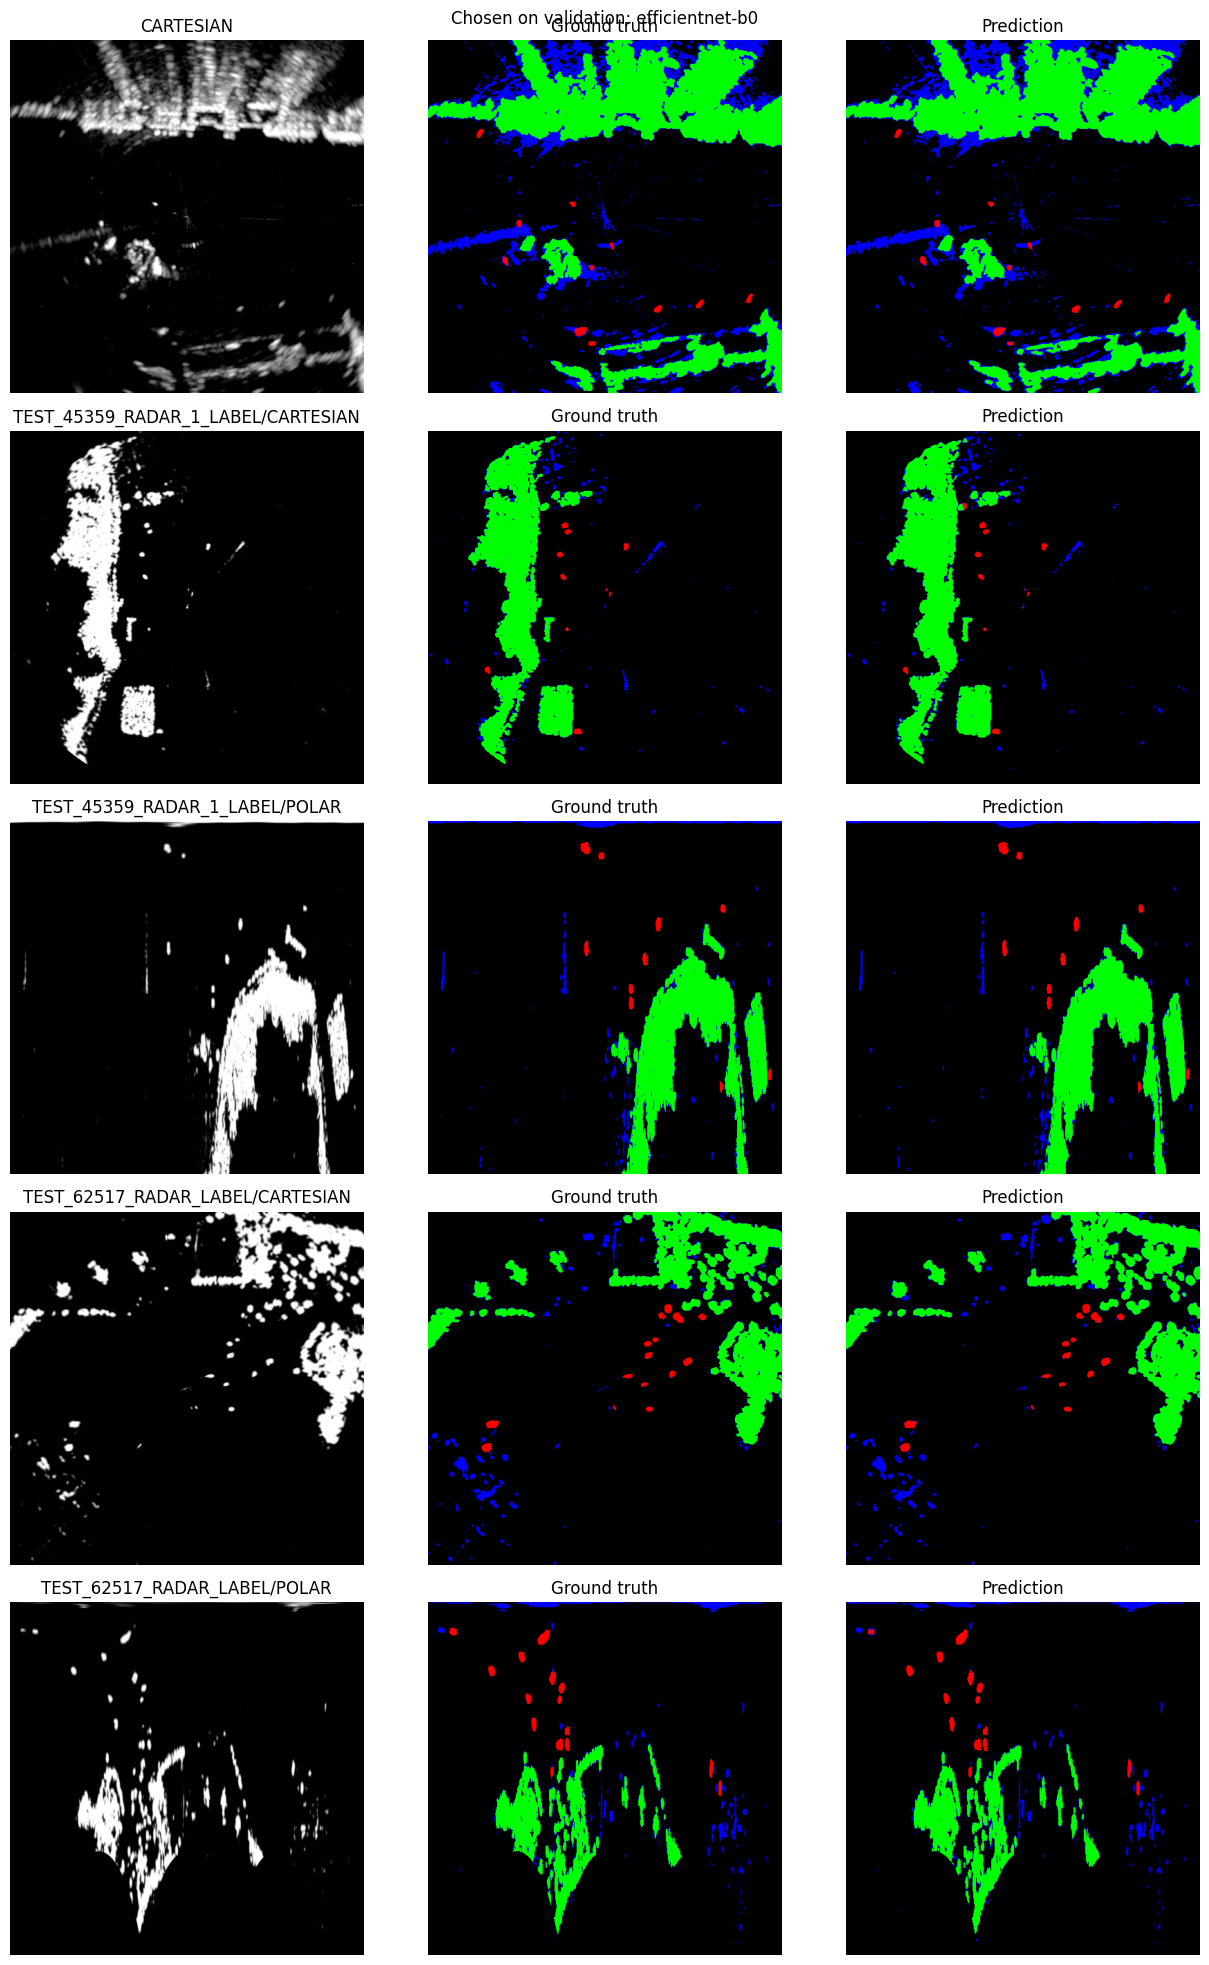

In [15]:
choice=max(completed,key=lambda r:r['best_val_dice'])
model=make_model(choice['model'],pretrained=False).to(DEVICE).eval()
ck=torch.load(choice['checkpoint'],map_location='cpu',weights_only=False);model.load_state_dict(ck['state']);del ck
items=[]
for branch in sorted(set(r['branch'] for r in subset('ALL','test'))):
    items.append(next(r for r in subset('ALL','test') if r['branch']==branch))
colors=np.array([unpack(k) for k in PALETTE],dtype=np.uint8)
fig,axes=plt.subplots(len(items),3,figsize=(13,4*len(items)),squeeze=False)
for i,r in enumerate(items):
    x,y=RadarDataset([r])[0]
    with torch.inference_mode(),torch.autocast(device_type=DEVICE,enabled=True):
        pred=model(x[None].to(DEVICE)).argmax(1)[0].cpu().numpy()
    with Image.open(r['image']) as im:original=np.asarray(im.convert('RGB').resize(IMAGE_SIZE[::-1],Image.Resampling.BILINEAR))
    for j,a in enumerate([original,colors[y.numpy()],colors[pred]]):
        axes[i,j].imshow(a);axes[i,j].axis('off')
        axes[i,j].set_title(['Radar','Ground truth','Prediction'][j])
    axes[i,0].set_title(r['branch'])
plt.suptitle('Chosen on validation: '+choice['model']);plt.tight_layout()
plt.savefig(OUT/'prediction_examples_all6.png',dpi=140,bbox_inches='tight');plt.show()


## What changes from the earlier notebook

- Loads the saved pairing manifest and fixed audited palette instead of repeating full color/dimension scans.
- Trains ResNet-18, ConvNeXt-Tiny and Swin-Tiny on ALL data.
- Restores original resolution from a baseline checkpoint; passes it explicitly to Swin.
- Calculates loss reductions in float32 for mixed-precision stability. The loss formula is unchanged.
- Uses the same SMP decoder configuration for the pretrained encoders; the custom baseline retains its original architecture.
- Saves resume state each epoch, completion markers, per-class and branch metrics, and a six-model CSV.
- Forward latency is recalculated for all six models using one consistent timer; previously printed latency included loss computation.

Run a GPU forward preflight before training. The notebook has been checked for Python syntax and its model configuration against the SMP 0.5 implementation, but training cannot be executed here without your Drive dataset and a GPU. Source independence and the provisional gray-to-background mapping still need dataset-specific verification.
